## Import Library

In [1]:
# Purnomo Jeremy Bambang_202431026
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("heart.csv") # Purnomo Jeremy Bambang_202431026

In [3]:
data.head() # Purnomo Jeremy Bambang_202431026

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
data.info() # Purnomo Jeremy Bambang_202431026

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [5]:
data.describe() # Purnomo Jeremy Bambang_202431026

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [6]:
# Purnomo Jeremy Bambang_202431026
# Mengambil kolom numerikal (target HeartDisease tidak dihitung sebagai fitur)
numerical_features = [feature for feature in data.columns if pd.api.types.is_numeric_dtype(data[feature]) and feature != 'HeartDisease']
print("Jumlah fitur numerik = ",
      len(numerical_features))
print("Daftar fitur numerik = ",
      numerical_features)
display(data[numerical_features].head())

Jumlah fitur numerik =  6
Daftar fitur numerik =  ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak
0,40,140,289,0,172,0.0
1,49,160,180,0,156,1.0
2,37,130,283,0,98,0.0
3,48,138,214,0,108,1.5
4,54,150,195,0,122,0.0


In [7]:
# Purnomo Jeremy Bambang_202431026
#Mengambil kolom kategorikal
categorical_features = [feature for feature in data.columns if not pd.api.types.is_numeric_dtype(data[feature])]
print("Jumlah fitur kategorikal = ",
      len(categorical_features))
print("Daftar fitur kategorikal = ",
      categorical_features)
display(data[categorical_features].head())

Jumlah fitur kategorikal =  5
Daftar fitur kategorikal =  ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,M,ATA,Normal,N,Up
1,F,NAP,Normal,N,Flat
2,M,ATA,ST,N,Up
3,F,ASY,Normal,Y,Flat
4,M,NAP,Normal,N,Up


In [8]:
# Purnomo Jeremy Bambang_202431026
# Menampilkan data unik pada fitur kategorikal
for i in categorical_features:
    print(i, ":", data[i].unique())

Sex : ['M' 'F']
ChestPainType : ['ATA' 'NAP' 'ASY' 'TA']
RestingECG : ['Normal' 'ST' 'LVH']
ExerciseAngina : ['N' 'Y']
ST_Slope : ['Up' 'Flat' 'Down']


In [9]:
# Purnomo Jeremy Bambang_202431026
# Mengubah kolom kategorikal menjadi angka untuk klasifikasi
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for feature in categorical_features:
    print(data[feature].unique())
    data[feature] = le.fit_transform(data[feature])
    print(data[feature].unique())

['M' 'F']
[1 0]
['ATA' 'NAP' 'ASY' 'TA']
[1 2 0 3]
['Normal' 'ST' 'LVH']
[1 2 0]
['N' 'Y']
[0 1]
['Up' 'Flat' 'Down']
[2 1 0]


In [10]:
data.head() # Purnomo Jeremy Bambang_202431026

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [11]:
# Purnomo Jeremy Bambang_202431026
# Mengambil kolom untuk fitur dan label
x = data.drop(['HeartDisease'], axis=1)
y = data['HeartDisease']
print(x)
print(y)

     Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
0     40    1              1        140          289          0           1   
1     49    0              2        160          180          0           1   
2     37    1              1        130          283          0           2   
3     48    0              0        138          214          0           1   
4     54    1              2        150          195          0           1   
..   ...  ...            ...        ...          ...        ...         ...   
913   45    1              3        110          264          0           1   
914   68    1              0        144          193          1           1   
915   57    1              0        130          131          0           1   
916   57    0              1        130          236          0           0   
917   38    1              2        138          175          0           1   

     MaxHR  ExerciseAngina  Oldpeak  ST_Slope  
0  

In [12]:
# Purnomo Jeremy Bambang_202431026
# Membagi data menjadi data test dan data train
from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size = 0.25, random_state = 0)

In [13]:
# Purnomo Jeremy Bambang_202431026
#melatih model Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(x_train, y_train)

,priors,None
,var_smoothing,1e-09


In [14]:
# Purnomo Jeremy Bambang_202431026
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Evaluasi Training
[[274  44]
 [ 51 319]]
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       318
           1       0.88      0.86      0.87       370

    accuracy                           0.86       688
   macro avg       0.86      0.86      0.86       688
weighted avg       0.86      0.86      0.86       688



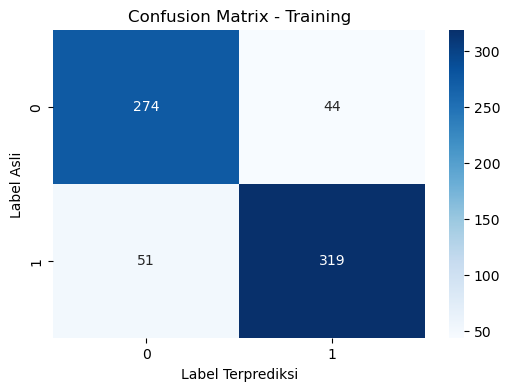

In [15]:
# Purnomo Jeremy Bambang_202431026
from sklearn.metrics import confusion_matrix, classification_report

print("Evaluasi Training")
cm_train = confusion_matrix(y_train, y_pred_train)
print(cm_train)
print(classification_report(y_train, y_pred_train))

plt.figure(figsize = (6, 4))
sns.heatmap(cm_train, annot = True, fmt='d', cmap = 'Blues', xticklabels = np.unique(y), yticklabels = np.unique(y))
plt.title("Confusion Matrix - Training")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show()

Evaluasi Testing
[[ 73  19]
 [ 16 122]]
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



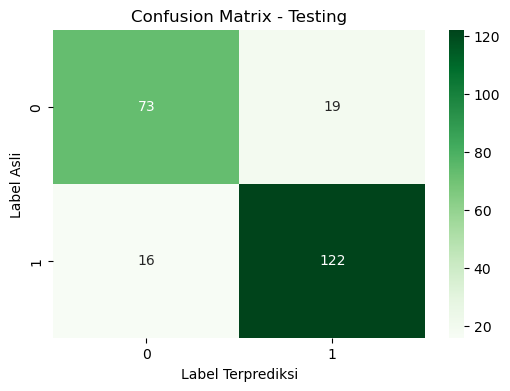

In [16]:
# Purnomo Jeremy Bambang_202431026
print("Evaluasi Testing")
cm_test = confusion_matrix(y_test, y_pred_test)
print(cm_test)
print(classification_report(y_test, y_pred_test))

plt.figure(figsize = (6, 4))
sns.heatmap(cm_test, annot = True, fmt='d', cmap = 'Greens', xticklabels = np.unique(y), yticklabels = np.unique(y))
plt.title("Confusion Matrix - Testing")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show()

In [17]:
# Purnomo Jeremy Bambang_202431026
# Uji dengan 1 data baru
data_baru = pd.DataFrame([[55, 1, 0, 140, 230, 0, 1, 120, 1, 1.5, 1]], columns = x.columns)
hasil = model.predict(data_baru)
print("Hasil prediksi:", hasil[0], "(1 = sakit jantung, 0 = normal)")

Hasil prediksi: 1 (1 = sakit jantung, 0 = normal)
